MD# 02 · Feature Engineering & Churn Prediction Models
Train and compare machine learning models that predict which customers will churn, then explain what drives the predictions.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from xgboost import XGBClassifier
STAY, CHURN = '#2a78d6', '#eb6834'
sns.set_theme(style='whitegrid')
df = pd.read_csv('../data/processed/churn_clean.csv')
df.shape

(7043, 21)

MD## 1. Feature engineering

In [2]:
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['NumServices'] = (df[services] == 'Yes').sum(axis=1) + (df['PhoneService'] == 'Yes')
df['AvgMonthlySpend'] = np.where(df['tenure'] > 0, df['TotalCharges'] / df['tenure'].replace(0, 1), df['MonthlyCharges'])
df['IsNewCustomer'] = (df['tenure'] <= 12).astype(int)
df['AutoPay'] = df['PaymentMethod'].str.contains('automatic').astype(int)

X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices', 'AvgMonthlySpend', 'IsNewCustomer', 'AutoPay']
cat_cols = [c for c in X.columns if c not in num_cols]
print(len(num_cols), 'numeric |', len(cat_cols), 'categorical features')

7 numeric | 16 categorical features


MD New features: **NumServices** (how many add-ons a customer uses), **AvgMonthlySpend**, **IsNewCustomer** (tenure ≤ 12 months — the high-risk group from EDA) and **AutoPay**.

MD## 2. Train/test split and preprocessing pipeline
A stratified 80/20 split keeps the 26.5% churn rate in both sets. Scaling and one-hot encoding live **inside** a scikit-learn `Pipeline`, so they are fit on training data only (no data leakage).

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_cols)])
print('Train:', X_train.shape, f'churn {y_train.mean():.1%}', '| Test:', X_test.shape, f'churn {y_test.mean():.1%}')

Train: (5634, 23) churn 26.5% | Test: (1409, 23) churn 26.5%


MD## 3. Compare three models with 5-fold cross-validation

In [4]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=spw, eval_metric='logloss', random_state=42)}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['roc_auc', 'recall', 'precision', 'f1'])
    rows.append({'model': name, **{k.replace('test_', 'cv_'): round(v.mean(), 3) for k, v in s.items() if k.startswith('test_')}})
cv_results = pd.DataFrame(rows).set_index('model')
cv_results

,cv_roc_auc,cv_recall,cv_precision,cv_f1
model,,,,
Logistic Regression,0.846,0.799,0.519,0.629
Random Forest,0.845,0.759,0.542,0.632
XGBoost,0.846,0.794,0.522,0.630


MD## 4. Hyperparameter tuning (GridSearchCV)

In [5]:
grid = GridSearchCV(
    Pipeline([('prep', preprocess), ('model', XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', subsample=0.8, colsample_bytree=0.8, random_state=42))]),
    param_grid={'model__n_estimators': [200, 400], 'model__max_depth': [2, 3, 4], 'model__learning_rate': [0.03, 0.05, 0.1]},
    scoring='roc_auc', cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
print('Best params:', grid.best_params_)
print(f'Best CV ROC-AUC: {grid.best_score_:.3f}')

Best params: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 400}
Best CV ROC-AUC: 0.850


MD## 5. Evaluate all models on the held-out test set

In [6]:
fitted = {name: Pipeline([('prep', preprocess), ('model', m)]).fit(X_train, y_train) for name, m in models.items()}
fitted['XGBoost (tuned)'] = grid.best_estimator_
test_rows = []
for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
    test_rows.append({'model': name, 'ROC-AUC': roc_auc_score(y_test, proba), 'Accuracy': accuracy_score(y_test, pred),
                      'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred)})
test_results = pd.DataFrame(test_rows).set_index('model').round(3)
test_results

,ROC-AUC,Accuracy,Precision,Recall,F1
model,,,,,
Logistic Regression,0.841,0.735,0.501,0.794,0.614
Random Forest,0.840,0.765,0.540,0.781,0.638
XGBoost,0.846,0.752,0.521,0.791,0.628
XGBoost (tuned),0.846,0.742,0.508,0.807,0.624


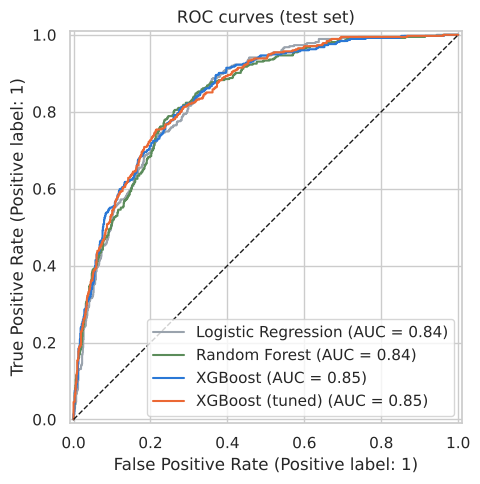

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
colors = ['#9aa3ad', '#5b8c5a', STAY, CHURN]
for (name, pipe), c in zip(fitted.items(), colors):
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name, curve_kwargs={'color': c})
ax.plot([0, 1], [0, 1], 'k--', lw=1); ax.set_title('ROC curves (test set)')
plt.tight_layout(); plt.savefig('../images/08_roc_curves.png', dpi=150); plt.show()

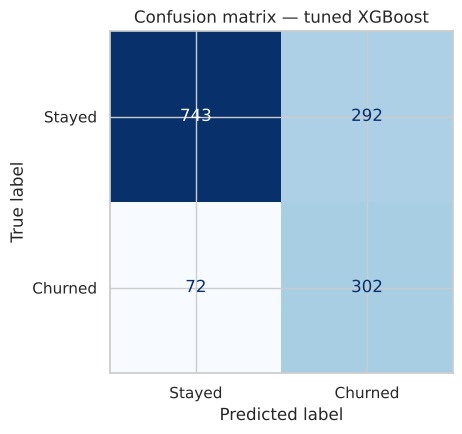

              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.51      0.81      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [8]:
best = fitted['XGBoost (tuned)']
proba = best.predict_proba(X_test)[:, 1]; pred = (proba >= 0.5).astype(int)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Stayed', 'Churned']).plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Confusion matrix — tuned XGBoost'); plt.tight_layout(); plt.savefig('../images/09_confusion_matrix.png', dpi=150); plt.show()
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))

MD## 6. What drives churn? (permutation importance)

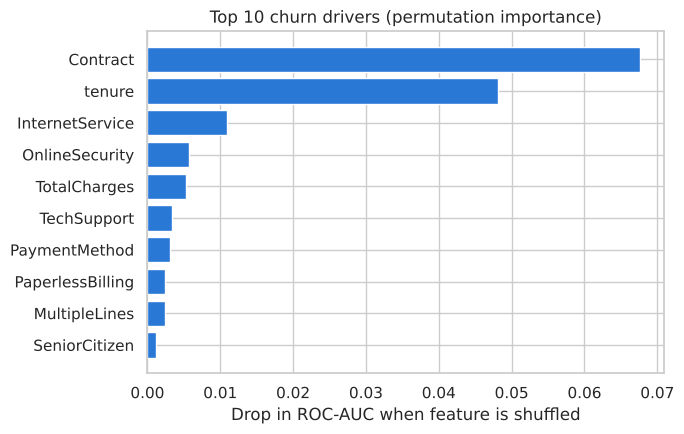

Contract            0.0676
tenure              0.0481
InternetService     0.0110
OnlineSecurity      0.0057
TotalCharges        0.0054
TechSupport         0.0033
PaymentMethod       0.0031
PaperlessBilling    0.0025
MultipleLines       0.0024
SeniorCitizen       0.0012
dtype: float64

In [9]:
imp = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=10, random_state=42, n_jobs=-1)
fi = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(fi.index, fi.values, color=STAY); ax.set_xlabel('Drop in ROC-AUC when feature is shuffled')
ax.set_title('Top 10 churn drivers (permutation importance)')
plt.tight_layout(); plt.savefig('../images/10_feature_importance.png', dpi=150); plt.show()
fi.sort_values(ascending=False).round(4)

MD## 7. Business view: who should the retention team call?
Rank test customers by predicted churn probability and check how many real churners are in the top 20%.

In [10]:
ranked = pd.DataFrame({'proba': proba, 'churn': y_test.values}).sort_values('proba', ascending=False)
top = ranked.head(int(len(ranked) * 0.2))
captured = top['churn'].sum() / ranked['churn'].sum()
print(f'Top 20% riskiest customers contain {captured:.0%} of all churners')
print(f'Churn rate in that group: {top.churn.mean():.0%} (vs {y_test.mean():.0%} overall) -> lift {top.churn.mean()/y_test.mean():.1f}x')

Top 20% riskiest customers contain 51% of all churners
Churn rate in that group: 68% (vs 27% overall) -> lift 2.5x


In [11]:
joblib.dump(best, '../models/churn_xgb_pipeline.joblib')
print('Saved model pipeline')

Saved model pipeline


MD## Results summary
- Three models compared with 5-fold stratified cross-validation; tuned **XGBoost** chosen as the final model.
- Class imbalance handled with class weights (`class_weight`, `scale_pos_weight`) instead of plain accuracy.
- Strongest churn drivers: **contract type, tenure, internet service (fiber) and monthly charges**.
- Targeting the **top 20% riskiest customers** reaches roughly half of all churners — a practical shortlist for a retention campaign.